<a href="https://colab.research.google.com/github/2025csnandinine-ship-it/dav-lab/blob/main/lab9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 18461    0 18461    0     0  38394      0 --:--:-- --:--:-- --:--:-- 38621
(297, 14)
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  HeartDisease  
0    3.0  0.0   6.0             0  
1    2.0  3.0   3.0             1  
2    2.0  2.0   7.0             1  
3    3.0  0.0   3.0             0  
4    1.0  0.0   3.0             0  
<class 'pandas.core.frame.DataFrame'>
Index: 297 entries, 0 to 301
Data co

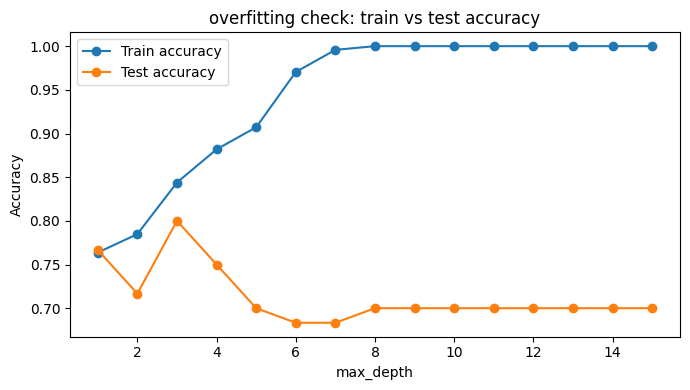


=== PRUNED TREE (max_depth=3) ===
Confusion matrix: 
 [[28  4]
 [ 8 20]]
TN=28 FP=4 FN=8 TP=20
Train acc: 0.8397
Test acc : 0.8
Precision : 0.8333
Recall : 0.7143
F1-score : 0.7692

               precision    recall  f1-score   support

  No disease       0.78      0.88      0.82        32
     Disease       0.83      0.71      0.77        28

    accuracy                           0.80        60
   macro avg       0.81      0.79      0.80        60
weighted avg       0.80      0.80      0.80        60



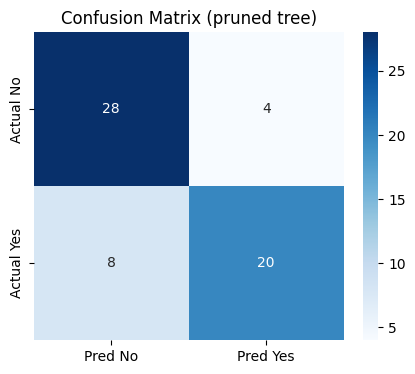

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
import os

# Remove corrupt file if it exists
if os.path.exists("heart.csv"):
    os.remove("heart.csv")

# Download a verified and active URL containing the UCI Heart Disease dataset
!curl -L -o heart.csv "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# Read the dataset (Cleveland dataset doesn't have headers in the raw file)
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "HeartDisease"
]
df = pd.read_csv("heart.csv", names=columns, na_values="?")

# Drop rows with missing values to keep things clean
df = df.dropna()

# Convert the target variable: UCI values are 0 (normal) and 1, 2, 3, 4 (heart disease)
# We'll map values > 0 to 1 (indicating presence of heart disease)
df["HeartDisease"] = df["HeartDisease"].apply(lambda x: 1 if x > 0 else 0)

print(df.shape)
print(df.head())
print(df.info())
print("\nMissing values:", df.isnull().sum().sum())
print("\nclass balance (1 = heart disease): \n", df["HeartDisease"].value_counts())

#2. PREPARE DATA
df = pd.get_dummies(df, drop_first=True, dtype=int)
X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Correcting the instantiation of DecisionTreeClassifier and fixing typo
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)
print("\n=== unrestrict tree ===")
print("depth  :", full_tree.get_depth())
print("leaves :", full_tree.get_n_leaves())
print("train acc  :", round(full_tree.score(X_train, y_train), 4))
print("test acc   :", round(full_tree.score(X_test, y_test), 4))

depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, marker="o", label="Train accuracy")
plt.plot(depths, test_acc, marker="o", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("overfitting check: train vs test accuracy")
plt.legend()
plt.tight_layout()
plt.savefig("depth_vs_accuracy.png")
plt.show()

tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_leaf=10,
    random_state=42
)
tree.fit(X_train, y_train)

y_pred = tree.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("\n=== PRUNED TREE (max_depth=3) ===")
print("Confusion matrix: \n", cm)
print(f"TN={tn} FP={fp} FN={fn} TP={tp}")
print("Train acc:", round(tree.score(X_train, y_train), 4))
print("Test acc :", round(accuracy_score(y_test, y_pred), 4))
print("Precision :", round(precision_score(y_test, y_pred), 4))
print("Recall :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("\n", classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Pred No", "Pred Yes"], yticklabels=["Actual No", "Actual Yes"])
plt.title("Confusion Matrix (pruned tree)")
plt.show()